In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 123

In [ ]:
df = pd.read_csv('UCI_Credit_Card.csv')

df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


# Experiment 0

In [ ]:
#melihat dimensi data set
print("Jumlah baris dan kolom:", df.shape)

Jumlah baris dan kolom: (30000, 25)


Dataset yang digunakan merupakan default of Credit Card Clients Dataset yang terdiri atas 30.000 observasi dan memuat informasi mengenai karakteristik demografis, jumlah kredit, riwayat pembayaran, tagihan, serta pembayaran nasabah kartu kredit. Dataset ini terdiri dari 30.000 baris dengan 25 variabel. Variabel target yang digunakan adalah default.payment.next.month, dengan nilai 0 menunjukkan nasabah tidak mengalami default dan nilai 1 menunjukkan nasabah mengalami default.

In [ ]:
#melihat informasi dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [ ]:
#melihat data kolom
print("Daftar kolom:")
for i, col in enumerate(df.columns):
    print(i, col)

Daftar kolom:
0 ID
1 LIMIT_BAL
2 SEX
3 EDUCATION
4 MARRIAGE
5 AGE
6 PAY_0
7 PAY_2
8 PAY_3
9 PAY_4
10 PAY_5
11 PAY_6
12 BILL_AMT1
13 BILL_AMT2
14 BILL_AMT3
15 BILL_AMT4
16 BILL_AMT5
17 BILL_AMT6
18 PAY_AMT1
19 PAY_AMT2
20 PAY_AMT3
21 PAY_AMT4
22 PAY_AMT5
23 PAY_AMT6
24 default.payment.next.month


In [ ]:
#mengecek machine value
missing = df.isnull().sum()

print("Jumlah missing value:")
print(missing)

print("\nTotal missing value:", df.isnull().sum().sum())

Jumlah missing value:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

Total missing value: 0


Berdasarkan hasil pemeriksaan, tidak ditemukan missing value pada dataset. Oleh karena itu, tidak diperlukan proses imputasi atau penghapusan observasi akibat nilai yang hilang. Dataset dapat langsung digunakan untuk tahap pemodelan setelah dilakukan preprocessing yang relevan.

In [ ]:
#cek duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 0


Hasil pemeriksaan menunjukkan bahwa tidak terdapat baris duplikat dalam dataset. Dengan demikian, seluruh observasi dapat dipertahankan dan tidak diperlukan penghapusan data berdasarkan kriteria duplicate.

In [ ]:
#nilai target
target = 'default.payment.next.month'

print(df[target].value_counts())

default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64


In [ ]:
print(
    df[target]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64


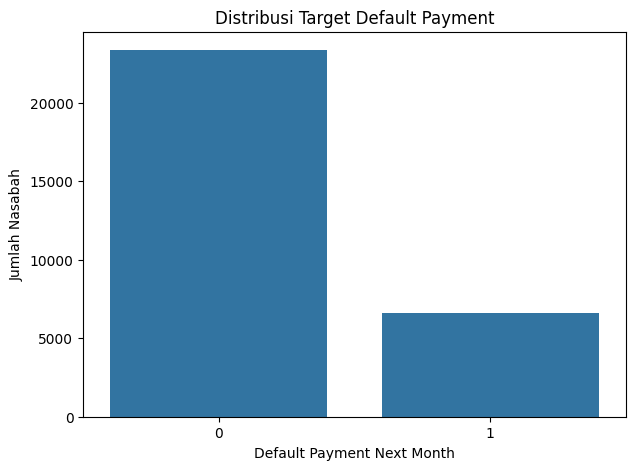

In [ ]:
#visualisasi distribusi target
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x=target
)

plt.title('Distribusi Target Default Payment')
plt.xlabel('Default Payment Next Month')
plt.ylabel('Jumlah Nasabah')

plt.show()

Hasil distribusi menunjukkan bahwa sebanyak 23.364 nasabah (77,88%) tidak mengalami default, sedangkan 6.636 nasabah (22,12%) mengalami default. Dengan demikian, data target mengalami ketidakseimbangan kelas, karena jumlah nasabah yang tidak default jauh lebih besar dibandingkan nasabah yang default. Kondisi ini menyebabkan accuracy saja kurang cukup untuk menilai performa model, sehingga metrik precision, recall, dan F1-score perlu diperhatikan, khususnya untuk kelas default.

In [ ]:
#menentukan predictor target
X = df.drop(columns=[target, 'ID'])
y = df[target]

print("Jumlah predictor:", X.shape[1])
print("Jumlah observasi:", X.shape[0])

Jumlah predictor: 23
Jumlah observasi: 30000


In [ ]:
#Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Data training :", X_train.shape)
print("Data testing  :", X_test.shape)

Data training : (24000, 23)
Data testing  : (6000, 23)


Data dibagi menjadi 80% data training (24.000 observasi) dan 20% data testing (6.000 observasi) dengan stratifikasi berdasarkan variabel target. Dengan demikian, proporsi kelas pada data training dan testing tetap mengikuti distribusi target awal.

In [ ]:
#fungsi evaluasi
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):

    # Training
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # 5-fold CV
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    cv_f1 = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='f1'
    )

    result = {
        'Experiment': model_name,
        'CV F1': cv_f1.mean(),
        'Test Accuracy': accuracy,
        'Test Precision': precision,
        'Test Recall': recall,
        'Test F1': f1
    }

    return result

# EXPERIMENT 1 - BASELINE MODEL

In [ ]:
#LOGISTIK REGRESION BASELINE

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

result_exp1 = evaluate_model(
    baseline_model,
    X_train,
    y_train,
    X_test,
    y_test,
    'Experiment 1 - Baseline Logistic Regression'
)

result_exp1

results = []

results.append(result_exp1)

results_df = pd.DataFrame(results)

results_df

,Experiment,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Experiment 1 - Baseline Logistic Regression,0.332756,0.800667,0.672823,0.192163,0.298945


Model Logistic Regression tanpa scaling menghasilkan CV F1 sebesar 0,3328, accuracy 80,07%, precision 67,28%, recall 19,22%, dan F1-score 29,89%. Meskipun accuracy mencapai 80,07%, recall hanya sebesar 19,22%. Artinya, model hanya mampu mengenali sebagian kecil nasabah yang benar-benar mengalami default. Dengan demikian, performa model belum baik dalam mendeteksi kelas default.

EXPERIMENT 2 - PREPROCESSING

In [ ]:
#membuat pipeline scaling + Logistic Regression
preprocessing_model = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

In [ ]:
#evaluasi experiment 2
result_exp2 = evaluate_model(
    preprocessing_model,
    X_train,
    y_train,
    X_test,
    y_test,
    'Experiment 2 - Logistic Regression + Scaling'
)

result_exp2

results.append(result_exp2)

results_df = pd.DataFrame(results)

results_df

,Experiment,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Experiment 1 - Baseline Logistic Regression,0.332756,0.800667,0.672823,0.192163,0.298945
1,Experiment 2 - Logistic Regression + Scaling,0.354912,0.811000,0.731415,0.229842,0.349771


Setelah dilakukan scaling, performa Logistic Regression meningkat. CV F1 naik dari 0,3328 menjadi 0,3549, sedangkan accuracy meningkat menjadi 81,10% dan F1-score menjadi 34,98%. Precision juga meningkat menjadi 73,14%, sementara recall meningkat menjadi 22,98%. Hal ini menunjukkan bahwa scaling memberikan perbaikan terhadap kemampuan model, meskipun kemampuan mendeteksi nasabah default masih relatif rendah.

# EXPERIMENT 3 - MODEL COMPARISON

In [ ]:
#regresi logistik
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

In [ ]:
#decision tree
decision_tree_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

In [ ]:
#Random forest
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [ ]:
#evaluasi model
result_logistic = evaluate_model(
    logistic_model,
    X_train,
    y_train,
    X_test,
    y_test,
    'Experiment 3 - Logistic Regression'
)

result_tree = evaluate_model(
    decision_tree_model,
    X_train,
    y_train,
    X_test,
    y_test,
    'Experiment 3 - Decision Tree'
)

result_rf = evaluate_model(
    random_forest_model,
    X_train,
    y_train,
    X_test,
    y_test,
    'Experiment 3 - Random Forest'
)

In [ ]:
comparison_exp3 = pd.DataFrame([
    result_logistic,
    result_tree,
    result_rf
])

comparison_exp3

comparison_exp3.sort_values(
    by='Test F1',
    ascending=False
)

,Experiment,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
2,Experiment 3 - Random Forest,0.469826,0.815667,0.650750,0.359457,0.463107
1,Experiment 3 - Decision Tree,0.406217,0.715833,0.365767,0.388093,0.376600
0,Experiment 3 - Logistic Regression,0.354912,0.811000,0.731415,0.229842,0.349771


In [ ]:
#menentukan model terbaik
best_exp3 = comparison_exp3.loc[
    comparison_exp3['Test F1'].idxmax()
]

print("Model terbaik Experiment 3:")
print(best_exp3)

Model terbaik Experiment 3:
Experiment        Experiment 3 - Random Forest
CV F1                                 0.469826
Test Accuracy                         0.815667
Test Precision                         0.65075
Test Recall                           0.359457
Test F1                               0.463107
Name: 2, dtype: object


Pada perbandingan tiga model, Random Forest memberikan performa terbaik dibandingkan Logistic Regression dan Decision Tree berdasarkan F1-score. Random Forest menghasilkan CV F1 0,4698, accuracy 81,57%, precision 65,08%, recall 35,95%, dan F1-score 46,31%.

Decision Tree menghasilkan F1-score 37,66%, sedangkan Logistic Regression hanya 34,98%. Dengan demikian, Random Forest lebih baik dalam menyeimbangkan precision dan recall untuk mendeteksi nasabah yang mengalami default.

EXPERIMENT 4 - HYPERPARAMETER TUNING

In [ ]:
#GridSearchCV Random Forest
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5,
             estimator=RandomForestClassifier(n_jobs=-1, random_state=123),
             n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='f1', verbose=1)

In [ ]:
#hyperparameter terbaik
print("Best Parameters:")
print(grid_search_rf.best_params_)

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [ ]:
#best CV F1
print("Best CV F1-score:")
print(grid_search_rf.best_score_)

Best CV F1-score:
0.4716591911811995


In [ ]:
#evaluasi model setelah tuning
best_rf = grid_search_rf.best_estimator_

y_pred_tuned = best_rf.predict(X_test)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(
    y_test,
    y_pred_tuned,
    zero_division=0
)
recall_tuned = recall_score(
    y_test,
    y_pred_tuned,
    zero_division=0
)
f1_tuned = f1_score(
    y_test,
    y_pred_tuned,
    zero_division=0
)

result_exp4 = {
    'Experiment': 'Experiment 4 - Tuned Random Forest',
    'CV F1': grid_search_rf.best_score_,
    'Test Accuracy': accuracy_tuned,
    'Test Precision': precision_tuned,
    'Test Recall': recall_tuned,
    'Test F1': f1_tuned
}

result_exp4

{'Experiment': 'Experiment 4 - Tuned Random Forest',
 'CV F1': np.float64(0.4716591911811995),
 'Test Accuracy': 0.815,
 'Test Precision': 0.6472184531886025,
 'Test Recall': 0.359457422758101,
 'Test F1': 0.4622093023255814}

Hasil GridSearchCV menunjukkan parameter terbaik adalah n_estimators = 200, max_depth = None, min_samples_split = 2, dan min_samples_leaf = 1. Model hasil tuning menghasilkan CV F1 0,4717, sedikit lebih tinggi dibandingkan Random Forest sebelum tuning (0,4698).

Namun, pada data testing F1-score justru sedikit turun dari 0,4631 menjadi 0,4622. Accuracy juga hampir sama, yaitu 81,50%. Artinya, tuning parameter memberikan peningkatan yang sangat kecil pada validasi dan belum memberikan peningkatan performa pada data testing.

# EXPERIMENT 5 - ADVANCED MODEL

In [ ]:
#Gradient Boosting
gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)

In [ ]:
#Evaluasi gradient boosting
result_exp5 = evaluate_model(
    gradient_boosting_model,
    X_train,
    y_train,
    X_test,
    y_test,
    'Experiment 5 - Gradient Boosting'
)

result_exp5

{'Experiment': 'Experiment 5 - Gradient Boosting',
 'CV F1': np.float64(0.47558592991289617),
 'Test Accuracy': 0.8236666666666667,
 'Test Precision': 0.6946454413892909,
 'Test Recall': 0.3617181612660136,
 'Test F1': 0.4757185332011893}

Gradient Boosting menghasilkan CV F1 sebesar 0,4756, accuracy 82,37%, precision 69,46%, recall 36,17%, dan F1-score 47,57%. Dibandingkan model sebelumnya, Gradient Boosting memberikan nilai F1-score testing tertinggi. Hal ini menunjukkan bahwa model tersebut memiliki keseimbangan precision dan recall yang paling baik dalam memprediksi nasabah yang mengalami default.

In [ ]:
#tabel semua eksperimen
final_results = pd.DataFrame([
    result_exp1,
    result_exp2,
    result_logistic,
    result_tree,
    result_rf,
    result_exp4,
    result_exp5
])

final_results

final_results = final_results.round(4)

final_results

,Experiment,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Experiment 1 - Baseline Logistic Regression,0.3328,0.8007,0.6728,0.1922,0.2989
1,Experiment 2 - Logistic Regression + Scaling,0.3549,0.8110,0.7314,0.2298,0.3498
2,Experiment 3 - Logistic Regression,0.3549,0.8110,0.7314,0.2298,0.3498
3,Experiment 3 - Decision Tree,0.4062,0.7158,0.3658,0.3881,0.3766
4,Experiment 3 - Random Forest,0.4698,0.8157,0.6508,0.3595,0.4631
5,Experiment 4 - Tuned Random Forest,0.4717,0.8150,0.6472,0.3595,0.4622
6,Experiment 5 - Gradient Boosting,0.4756,0.8237,0.6946,0.3617,0.4757


Hasil eksperimen menunjukkan adanya peningkatan performa dari model sederhana menuju model ensemble. Logistic Regression menghasilkan F1-score 29,89%, kemudian meningkat menjadi 34,98% setelah scaling. Random Forest menghasilkan F1-score 46,31%, sedangkan tuning Random Forest hanya menghasilkan 46,22% pada data testing. Gradient Boosting memberikan hasil terbaik dengan F1-score 47,57%. Hal ini menunjukkan bahwa pemilihan algoritma memberikan pengaruh yang lebih besar dibandingkan tuning Random Forest pada eksperimen ini.

In [ ]:
#menentukan model final
best_final = final_results.loc[
    final_results['Test F1'].idxmax()
]

print("===================================")
print("MODEL FINAL")
print("===================================")

print("Model :", best_final['Experiment'])
print("CV F1 :", best_final['CV F1'])
print("Accuracy :", best_final['Test Accuracy'])
print("Precision:", best_final['Test Precision'])
print("Recall   :", best_final['Test Recall'])
print("F1-score :", best_final['Test F1'])

MODEL FINAL
Model : Experiment 5 - Gradient Boosting
CV F1 : 0.4756
Accuracy : 0.8237
Precision: 0.6946
Recall   : 0.3617
F1-score : 0.4757


Secara keseluruhan, Gradient Boosting merupakan model terbaik karena menghasilkan Test F1-score tertinggi sebesar 0,4757, sekaligus memiliki accuracy tertinggi sebesar 82,37%. Model ini juga memiliki precision 69,46% dan recall 36,17%.

Berdasarkan seluruh eksperimen, Gradient Boosting dipilih sebagai model final karena memberikan performa terbaik berdasarkan F1-score. Model menghasilkan CV F1 0,4756, accuracy 82,37%, precision 69,46%, recall 36,17%, dan F1-score 47,57%. Namun, recall yang masih sekitar 36% menunjukkan bahwa model belum mampu mendeteksi seluruh nasabah yang berpotensi mengalami default. Oleh karena itu, model sudah memberikan performa terbaik di antara model yang diuji, tetapi masih memiliki ruang untuk ditingkatkan terutama dalam meningkatkan kemampuan mendeteksi kelas default.